# B3 v6 — Expanded Grid Search

**Purpose**: Broaden the parameter search after the v5 cache-bug fix revealed
that `mid_plus_1tick` holdout Sharpe is +1.11 (not +0.22 as the bugged v5 showed).
The v6 grid adds:
- `target_delta=0.12` (very OTM) and `0.50` (straddle)
- `dte_max=21` (weekly-style) and `60` (longer tenor)
- `profit_target_pct=0.25` and `0.75` (restored from v3)
- `manage_at_dte=5` and `21`
- `rv_pct:70` and `rv_pct:90` vol filters
- `defensive_leg_roll=True` (restored)
- `stop_loss_pct=2.0` (tighter stop)
- `mid_minus_1tick` dropped (consistently worst, no new information)

**Grid**: 6×4×3×4×4×2×2×3×1 = 13,824 raw combos → ~12,096 valid
**Runs**: train (2018-2022) + holdout (2023-2025) = ~24,192 backtests
**Estimated runtime**: ~45-60 min on 8 cores

**Market**: BOVA11 (B3 ETF), mode=market, cash_yield=0, use_cdi_ivs=True
**Fixed cache**: engine._exec_mode set per combo (cache bug from v5 resolved)

## 1. Imports

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(ROOT / 'src'))
from grid_search import run_grid, enumerate_grid, GRID_DIMS, DTE_MIN_BY_DTE_MAX

OUT_DIR      = ROOT / 'data' / 'B3'
RESULTS_PATH = OUT_DIR / 'v6_grid_search_results.parquet'
DB_PATH      = ROOT / 'data' / 'B3' / 'b3_options_rb3.db'

## 2. Grid Definition

Key additions vs v5: `delta=0.12/0.50`, `dte=21/60`, `profit=0.25/0.75`,
`manage=5/21`, `rv_pct:70/90`, `leg_roll=True`, `stop=2.0`.
`mid_minus_1tick` dropped (consistently worst in v5).

In [2]:
GRID = {
    "target_delta": [0.12, 0.16, 0.20, 0.25, 0.30, 0.50],
    "dte_max": [21, 30, 45, 60],
    "profit_target_pct": [0.25, 0.50, 0.75],
    "manage_at_dte": [5, 7, 14, 21],
    "vix_filter": ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90"],
    "defensive_leg_roll": [True, False],
    "stop_loss_pct": [2.0, 3.0],
    "execution_mode": ["bid_ask", "mid", "mid_plus_1tick"],
    "portfolio_mode": ["laddering"],
}
# Raw: 6×4×3×4×4×2×2×3×1 = 13,824
combos = enumerate_grid(GRID)
print(f"Grid: {len(combos)} valid combos × 2 periods = {len(combos) * 2} backtests")

# Validity breakdown by dte_max
for dte in [21, 30, 45, 60]:
    n = sum(1 for c in combos if c["dte_max"] == dte)
    dte_min = DTE_MIN_BY_DTE_MAX[dte]
    print(f"  dte_max={dte} (dte_min={dte_min}): {n} combos")

Grid: 13824 raw combos, 12096 after validity filter (1728 dropped)
Grid: 12096 valid combos × 2 periods = 24192 backtests
  dte_max=21 (dte_min=15): 2592 combos
  dte_max=30 (dte_min=20): 2592 combos
  dte_max=45 (dte_min=30): 3456 combos
  dte_max=60 (dte_min=45): 3456 combos


## 3. Run Configuration

In [3]:
RUNS = [
    ("train", "bova11", "2018-01-02", "2022-12-31"),
    ("holdout", "bova11", "2023-01-02", "2025-11-30"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2018-01-02', '2022-12-31')
('holdout', 'bova11', '2023-01-02', '2025-11-30')


## 4. Execute Grid Search

Runs ~24,192 backtests. Skips if results already cached.
Estimated runtime: ~45-60 min on 8 cores.

In [4]:
if RESULTS_PATH.exists():
    print(f"Loading cached results from {RESULTS_PATH}")
    results = pd.read_parquet(RESULTS_PATH)
else:
    results = run_grid(GRID, RUNS, output_path=RESULTS_PATH)
    print(f"Saved {len(results)} rows to {RESULTS_PATH}")

# Filter to valid completed runs
df = results[results["error"].isna() & (results["n_trades"] >= 30)].copy()
df["execution_mode"] = pd.Categorical(
    df["execution_mode"],
    categories=["bid_ask", "mid", "mid_plus_1tick"],
    ordered=True,
)
df["delta_label"] = df["target_delta"].apply(
    lambda x: f"{int(x*100)}Δ" if x < 0.50 else "ATM(50Δ)"
)
holdout = df[df["period_label"] == "holdout"]
train = df[df["period_label"] == "train"]

n_err = int(results["error"].notna().sum())
n_few = int((results["n_trades"] < 30).sum())
print(f"Total: {len(results)} rows | errors={n_err} | n_trades<30={n_few}")
print(f"Valid: {len(df)} rows | train={len(train)} | holdout={len(holdout)}")

Loading cached results from /Users/oliversteiner/Documents/code/options-backtest/data/B3/v6_grid_search_results.parquet
Total: 24192 rows | errors=455 | n_trades<30=455
Valid: 23737 rows | train=11641 | holdout=12096


## Cell A — Sharpe vs Execution Mode

Central question: does the break-even execution level hold in the expanded grid?
Vertical red line at y=0.

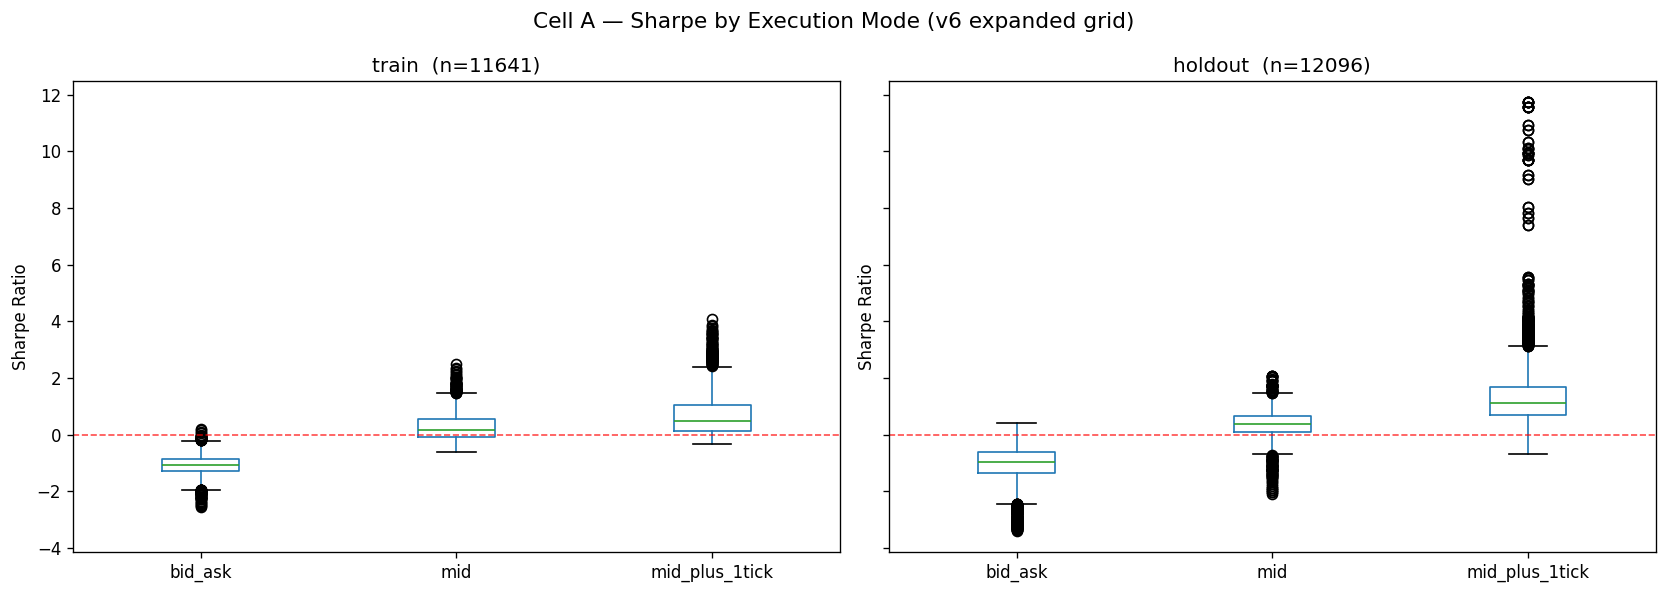


  mode                    train_p25  train_med  train_p75  hold_p25   hold_med   hold_p75
  bid_ask                    -1.287     -1.061     -0.854    -1.345     -0.955     -0.614
  mid                        -0.085      0.152      0.542     0.105      0.368      0.655
  mid_plus_1tick              0.131      0.487      1.042     0.699      1.110      1.672


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (period, period_df) in zip(axes, [("train", train), ("holdout", holdout)]):
    period_df.boxplot(column="sharpe", by="execution_mode", ax=ax, grid=False, rot=0)
    ax.set_title(f"{period}  (n={len(period_df)})", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Sharpe Ratio")
    ax.axhline(y=0, color="red", linestyle="--", linewidth=1, alpha=0.7)
fig.suptitle("Cell A — Sharpe by Execution Mode (v6 expanded grid)", fontsize=13)
plt.tight_layout()
plt.show()

# Numeric summary
modes = ["bid_ask", "mid", "mid_plus_1tick"]
print(
    f'\n  {"mode":<22} {"train_p25":>10} {"train_med":>10} {"train_p75":>10}'
    f'{"hold_p25":>10} {"hold_med":>10} {"hold_p75":>10}'
)
for mode in modes:
    tr = train[train["execution_mode"] == mode]["sharpe"]
    ho = holdout[holdout["execution_mode"] == mode]["sharpe"]
    print(
        f"  {mode:<22} {tr.quantile(0.25):>10.3f} {tr.median():>10.3f} {tr.quantile(0.75):>10.3f}"
        f"{ho.quantile(0.25):>10.3f} {ho.median():>10.3f} {ho.quantile(0.75):>10.3f}"
    )

## Cell B — Break-even Execution Level

Leftmost execution mode where holdout median Sharpe crosses zero.

In [6]:
modes = ["bid_ask", "mid", "mid_plus_1tick"]
break_even = None
print(f'  {"mode":<22} {"train_median":>14} {"holdout_median":>15}')
print("  " + "-" * 55)
for mode in modes:
    tr_med = train[train["execution_mode"] == mode]["sharpe"].median()
    ho_med = holdout[holdout["execution_mode"] == mode]["sharpe"].median()
    print(f"  {mode:<22} {tr_med:>+14.4f} {ho_med:>+15.4f}")
    if break_even is None and ho_med > 0:
        break_even = mode

if break_even:
    print(
        f"\nBreak-even execution: **{break_even}** "
        f"(leftmost mode with positive holdout median Sharpe)"
    )
else:
    print("\nNo break-even — all modes have negative median holdout Sharpe")

  mode                     train_median  holdout_median
  -------------------------------------------------------
  bid_ask                       -1.0607         -0.9551
  mid                           +0.1521         +0.3678
  mid_plus_1tick                +0.4869         +1.1101

Break-even execution: **mid** (leftmost mode with positive holdout median Sharpe)


## Cell C — Execution Sensitivity by Delta

Heatmap: rows = execution_mode, columns = target_delta.
Does the straddle (50Δ) outperform OTM strangles under mid_plus_1tick?

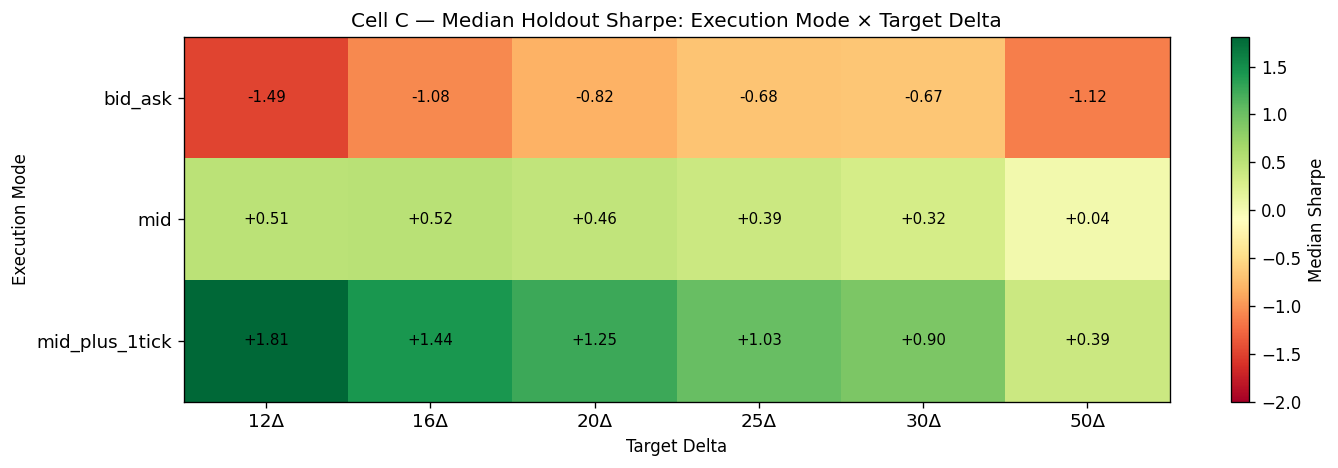

In [7]:
pivot = holdout.pivot_table(
    values="sharpe", index="execution_mode", columns="target_delta", aggfunc="median"
)
pivot.columns = [f"{int(c*100)}Δ" if c < 0.50 else "50Δ" for c in pivot.columns]

fig, ax = plt.subplots(figsize=(12, 4))
vmax = max(0.5, pivot.values[~np.isnan(pivot.values)].max())
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=-2, vmax=vmax)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=11)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=11)
ax.set_xlabel("Target Delta")
ax.set_ylabel("Execution Mode")
ax.set_title("Cell C — Median Holdout Sharpe: Execution Mode × Target Delta")
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        v = pivot.iloc[i, j]
        ax.text(
            j,
            i,
            f"{v:+.2f}" if not np.isnan(v) else "n/a",
            ha="center",
            va="center",
            fontsize=9,
        )
plt.colorbar(im, ax=ax, label="Median Sharpe")
plt.tight_layout()
plt.show()

## Cell D — DTE × Delta Heatmap (holdout, all execution modes)

Heatmap: rows = dte_max, columns = target_delta.
Which expiry cycle + delta combination is most robust across execution modes?

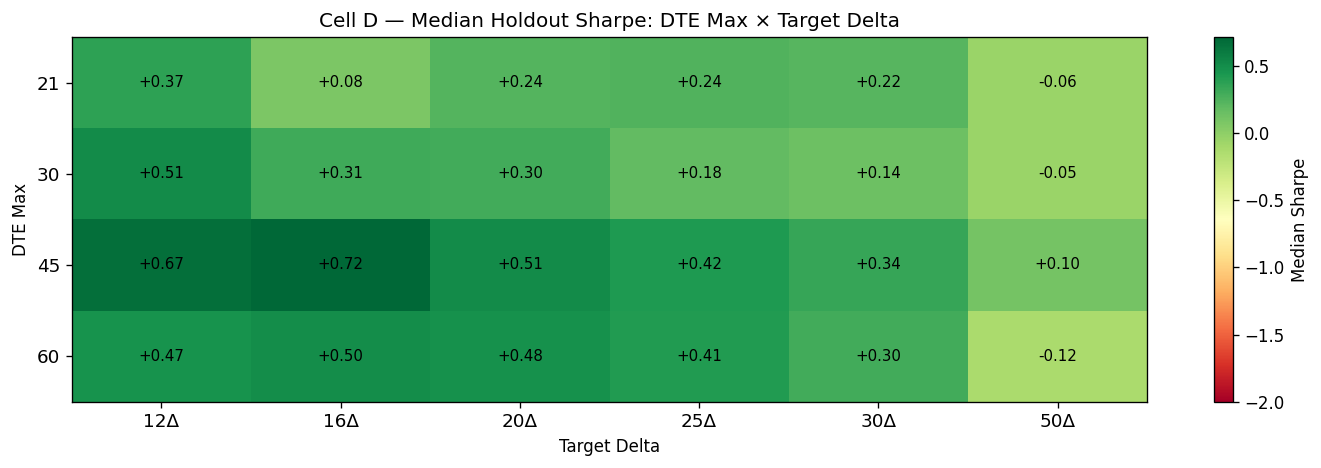

In [8]:
pivot_d = holdout.pivot_table(
    values="sharpe", index="dte_max", columns="target_delta", aggfunc="median"
)
pivot_d.columns = [f"{int(c*100)}Δ" if c < 0.50 else "50Δ" for c in pivot_d.columns]

fig, ax = plt.subplots(figsize=(12, 4))
vmax_d = max(0.5, pivot_d.values[~np.isnan(pivot_d.values)].max())
im2 = ax.imshow(pivot_d.values, aspect="auto", cmap="RdYlGn", vmin=-2, vmax=vmax_d)
ax.set_xticks(range(len(pivot_d.columns)))
ax.set_xticklabels(pivot_d.columns, fontsize=11)
ax.set_yticks(range(len(pivot_d.index)))
ax.set_yticklabels(pivot_d.index, fontsize=11)
ax.set_xlabel("Target Delta")
ax.set_ylabel("DTE Max")
ax.set_title("Cell D — Median Holdout Sharpe: DTE Max × Target Delta")
for i in range(len(pivot_d.index)):
    for j in range(len(pivot_d.columns)):
        v = pivot_d.iloc[i, j]
        ax.text(
            j,
            i,
            f"{v:+.2f}" if not np.isnan(v) else "n/a",
            ha="center",
            va="center",
            fontsize=9,
        )
plt.colorbar(im2, ax=ax, label="Median Sharpe")
plt.tight_layout()
plt.show()

## Cell E — Defensive Leg Roll Comparison

Same parameter sets, True vs False. Does active leg management help or hurt?
Comparison restricted to configs where both exist.

Holdout median Sharpe by execution_mode × defensive_leg_roll:
  mode                     roll=False    roll=True      delta
  ------------------------------------------------------------
  bid_ask                     -0.8893      -1.0024    -0.1131
  mid                         +0.4053      +0.3451    -0.0602
  mid_plus_1tick              +1.1015      +1.1272    +0.0256


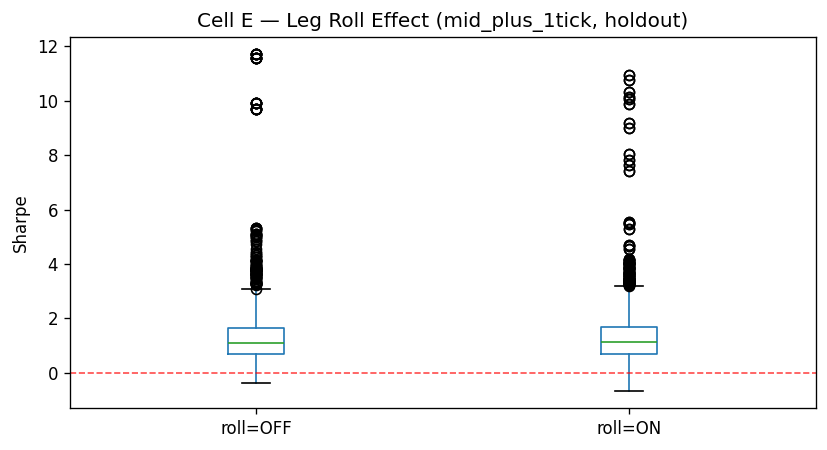

In [9]:
roll_on = holdout[holdout["defensive_leg_roll"] == True]
roll_off = holdout[holdout["defensive_leg_roll"] == False]

print("Holdout median Sharpe by execution_mode × defensive_leg_roll:")
print(f'  {"mode":<22} {"roll=False":>12} {"roll=True":>12} {"delta":>10}')
print("  " + "-" * 60)
for mode in modes:
    off = roll_off[roll_off["execution_mode"] == mode]["sharpe"].median()
    on = roll_on[roll_on["execution_mode"] == mode]["sharpe"].median()
    print(f"  {mode:<22} {off:>+12.4f} {on:>+12.4f} {on - off:>+10.4f}")

# Box comparison for best mode
best_mode = holdout.groupby("execution_mode")["sharpe"].median().idxmax()
sub = holdout[holdout["execution_mode"] == best_mode].copy()
sub["roll_label"] = sub["defensive_leg_roll"].map({True: "roll=ON", False: "roll=OFF"})
fig, ax = plt.subplots(figsize=(7, 4))
sub.boxplot(column="sharpe", by="roll_label", ax=ax, grid=False)
ax.axhline(y=0, color="red", linestyle="--", linewidth=1, alpha=0.7)
ax.set_title(f"Cell E — Leg Roll Effect ({best_mode}, holdout)")
ax.set_xlabel("")
ax.set_ylabel("Sharpe")
fig.suptitle("")
plt.tight_layout()
plt.show()

## Cell F — Straddle (50Δ) vs Strangle Comparison

Does selling ATM (50Δ) outperform OTM strangles net of the higher premium?
Compare by execution mode in holdout.

Holdout median Sharpe — Straddle (50Δ) vs OTM Strangle:
  mode                       strangle     straddle      delta
  ------------------------------------------------------------
  bid_ask                     -0.8731      -1.1242    -0.2511
  mid                         +0.4400      +0.0361    -0.4039
  mid_plus_1tick              +1.2398      +0.3924    -0.8475


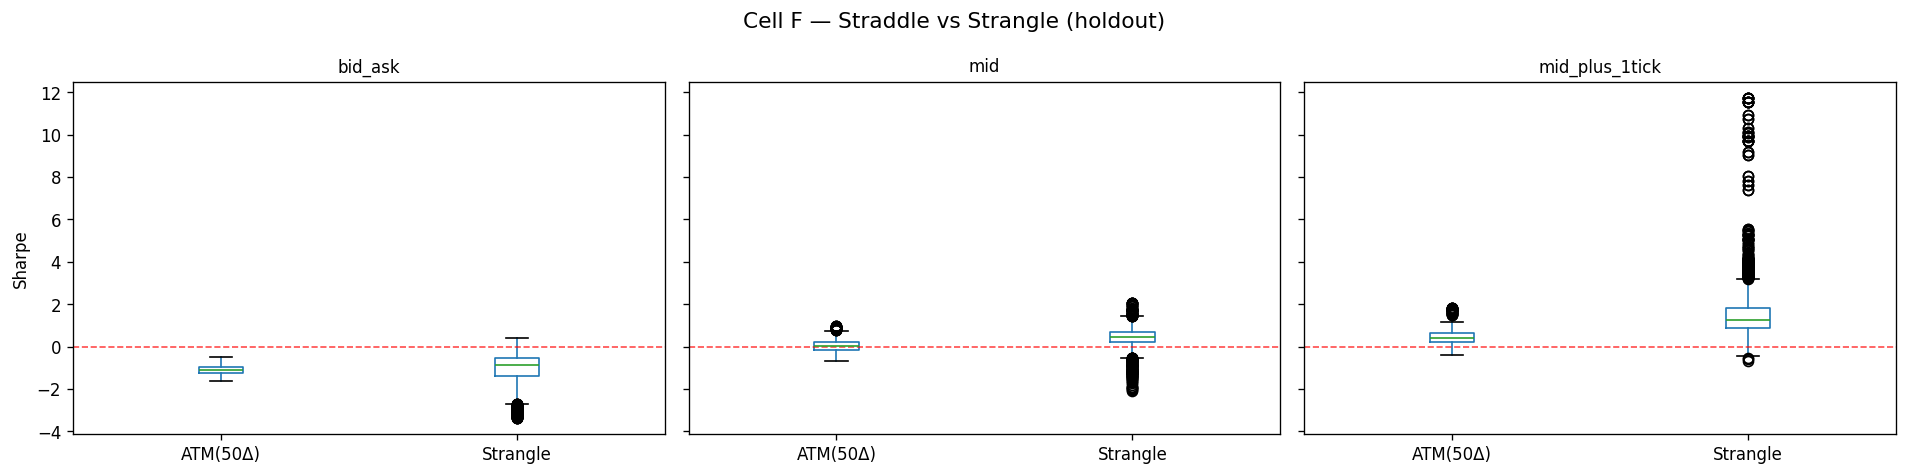

In [10]:
straddle = holdout[holdout["target_delta"] == 0.50]
strangle = holdout[holdout["target_delta"] != 0.50]

print("Holdout median Sharpe — Straddle (50Δ) vs OTM Strangle:")
print(f'  {"mode":<22} {"strangle":>12} {"straddle":>12} {"delta":>10}')
print("  " + "-" * 60)
for mode in modes:
    str_med = strangle[strangle["execution_mode"] == mode]["sharpe"].median()
    strad_med = straddle[straddle["execution_mode"] == mode]["sharpe"].median()
    d = strad_med - str_med
    print(f"  {mode:<22} {str_med:>+12.4f} {strad_med:>+12.4f} {d:>+10.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, mode in zip(axes, modes):
    sub = holdout[holdout["execution_mode"] == mode].copy()
    sub["type"] = sub["target_delta"].apply(
        lambda x: "ATM(50Δ)" if x == 0.50 else "Strangle"
    )
    sub.boxplot(column="sharpe", by="type", ax=ax, grid=False)
    ax.axhline(y=0, color="red", linestyle="--", lw=1, alpha=0.7)
    ax.set_title(mode, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Sharpe" if mode == "bid_ask" else "")
fig.suptitle("Cell F — Straddle vs Strangle (holdout)", fontsize=13)
plt.tight_layout()
plt.show()

## Cell G — Vol Filter Comparison

4 vol filter levels (OFF, rv_pct:70, rv_pct:80, rv_pct:90) by execution mode.
Does filtering high-vol environments improve results?

Holdout median Sharpe by vol_filter × execution_mode:
  vol_filter               bid_ask             mid  mid_plus_1tick
  ----------------------------------------------------------------
  OFF                      -0.9536         +0.3097         +1.0750
  rv_pct:70                -0.9221         +0.4170         +1.1679
  rv_pct:80                -0.9762         +0.3931         +1.1164
  rv_pct:90                -0.9636         +0.3616         +1.1014


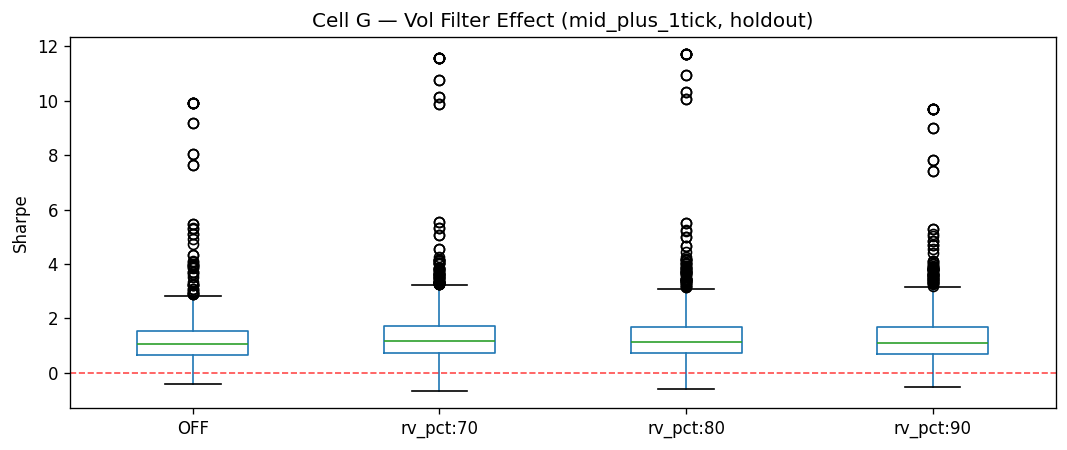

In [11]:
vf_order = ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90"]
print("Holdout median Sharpe by vol_filter × execution_mode:")
print(f'  {"vol_filter":<16}', end="")
for m in modes:
    print(f"{m:>16}", end="")
print()
print("  " + "-" * (16 + 16 * len(modes)))
for vf in vf_order:
    row = holdout[holdout["vix_filter"] == vf]
    print(f"  {vf:<16}", end="")
    for m in modes:
        med = row[row["execution_mode"] == m]["sharpe"].median()
        print(f"{med:>+16.4f}", end="")
    print()

# Boxplot for best mode
best_mode = holdout.groupby("execution_mode")["sharpe"].median().idxmax()
sub = holdout[holdout["execution_mode"] == best_mode].copy()
sub["vix_filter"] = pd.Categorical(sub["vix_filter"], categories=vf_order, ordered=True)
fig, ax = plt.subplots(figsize=(9, 4))
sub.boxplot(column="sharpe", by="vix_filter", ax=ax, grid=False)
ax.axhline(y=0, color="red", linestyle="--", lw=1, alpha=0.7)
ax.set_title(f"Cell G — Vol Filter Effect ({best_mode}, holdout)")
ax.set_xlabel("")
ax.set_ylabel("Sharpe")
fig.suptitle("")
plt.tight_layout()
plt.show()

## Cell H — Stop Loss Comparison (2.0× vs 3.0× premium)

Tighter stop (2.0×) vs wider stop (3.0×) across execution modes.

Holdout median Sharpe by stop_loss_pct × execution_mode:
     stop_loss             bid_ask                 mid      mid_plus_1tick
  ------------------------------------------------------------------------
           2.0             -1.0563             +0.3793             +1.1391
           3.0             -0.8753             +0.3548             +1.0767


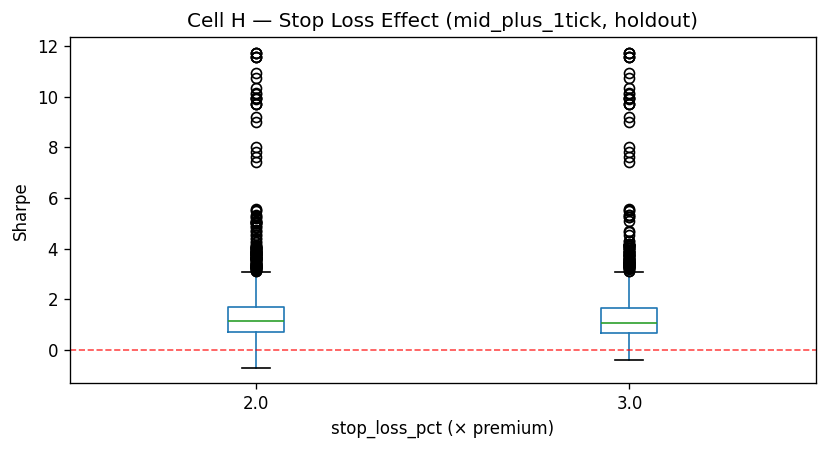

In [12]:
print("Holdout median Sharpe by stop_loss_pct × execution_mode:")
print(f'  {"stop_loss":>12}', end="")
for m in modes:
    print(f"{m:>20}", end="")
print()
print("  " + "-" * (12 + 20 * len(modes)))
for stop in [2.0, 3.0]:
    sub = holdout[holdout["stop_loss_pct"] == stop]
    print(f"  {stop:>12.1f}", end="")
    for m in modes:
        med = sub[sub["execution_mode"] == m]["sharpe"].median()
        print(f"{med:>+20.4f}", end="")
    print()

best_mode = holdout.groupby("execution_mode")["sharpe"].median().idxmax()
sub = holdout[holdout["execution_mode"] == best_mode].copy()
fig, ax = plt.subplots(figsize=(7, 4))
sub.boxplot(column="sharpe", by="stop_loss_pct", ax=ax, grid=False)
ax.axhline(y=0, color="red", linestyle="--", lw=1, alpha=0.7)
ax.set_title(f"Cell H — Stop Loss Effect ({best_mode}, holdout)")
ax.set_xlabel("stop_loss_pct (× premium)")
ax.set_ylabel("Sharpe")
fig.suptitle("")
plt.tight_layout()
plt.show()

## Cell I — Train vs Holdout Scatter

Scatter of per-config train Sharpe vs holdout Sharpe.
Configs in Q1 (both positive) are the most robust.

Configs with both train+holdout data: 11641
Q1 (both positive): 5427 (46.6%)


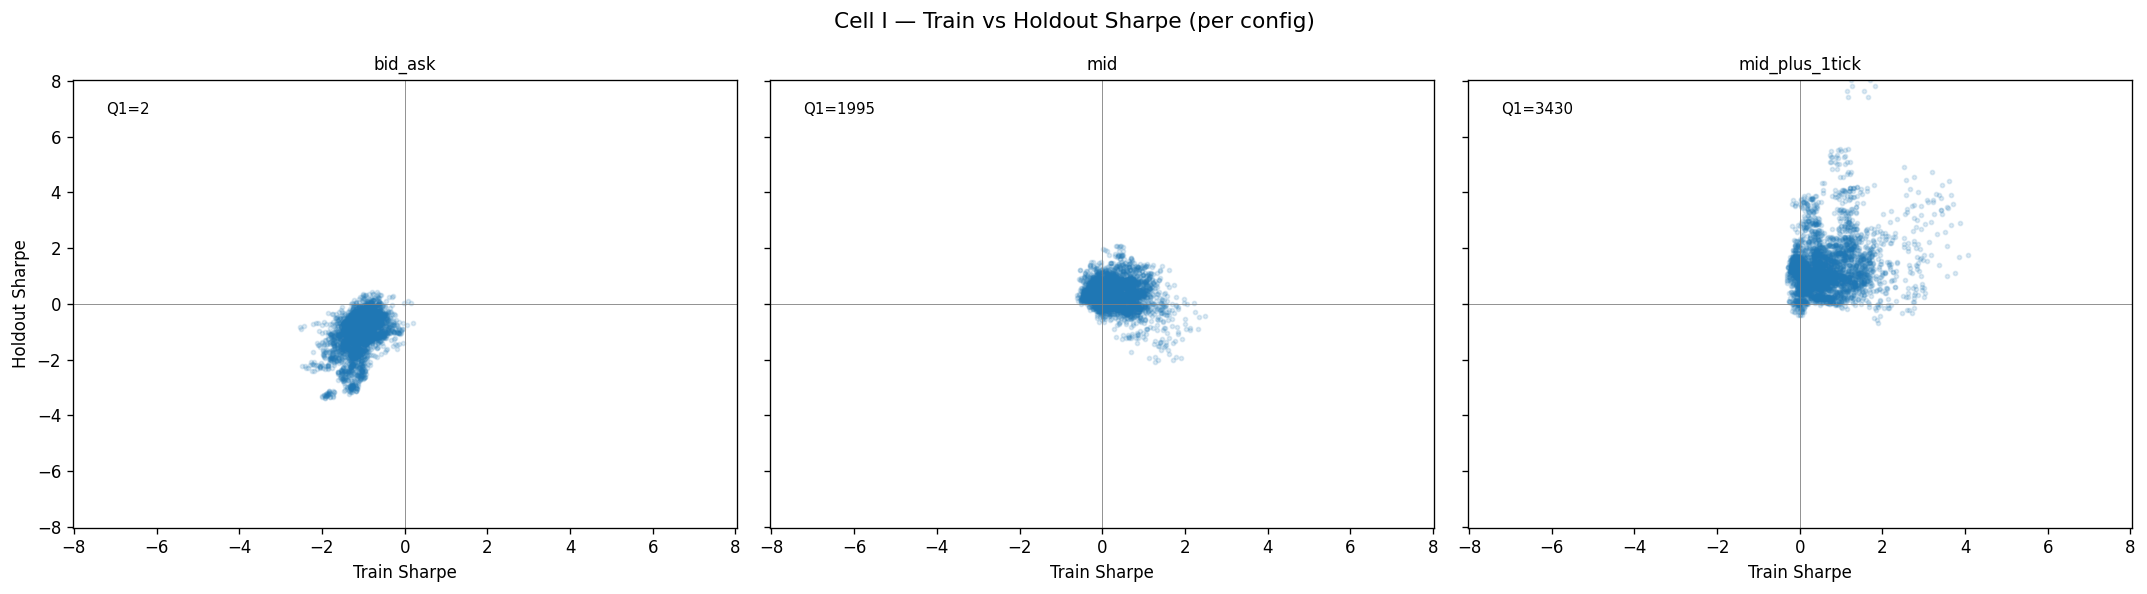

In [13]:
# Merge train and holdout by all GRID dimensions
merge_cols = [
    c
    for c in [
        "target_delta",
        "dte_max",
        "profit_target_pct",
        "manage_at_dte",
        "vix_filter",
        "defensive_leg_roll",
        "stop_loss_pct",
        "execution_mode",
        "portfolio_mode",
    ]
    if c in df.columns
]
df_train = train.set_index(merge_cols)[["sharpe"]].rename(
    columns={"sharpe": "sharpe_train"}
)
df_holdout = holdout.set_index(merge_cols)[["sharpe"]].rename(
    columns={"sharpe": "sharpe_holdout"}
)
scatter_df = df_train.join(df_holdout, how="inner").reset_index()

print(f"Configs with both train+holdout data: {len(scatter_df)}")
q1 = ((scatter_df["sharpe_train"] > 0) & (scatter_df["sharpe_holdout"] > 0)).sum()
print(f"Q1 (both positive): {q1} ({q1/len(scatter_df)*100:.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True, sharex=True)
for ax, mode in zip(axes, modes):
    sub = scatter_df[scatter_df["execution_mode"] == mode]
    ax.scatter(sub["sharpe_train"], sub["sharpe_holdout"], alpha=0.15, s=6)
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(mode, fontsize=10)
    ax.set_xlabel("Train Sharpe")
    ax.set_ylabel("Holdout Sharpe" if mode == "bid_ask" else "")
    lim = max(
        abs(sub["sharpe_train"].quantile([0.01, 0.99])).max(),
        abs(sub["sharpe_holdout"].quantile([0.01, 0.99])).max(),
    )
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    q1_sub = ((sub["sharpe_train"] > 0) & (sub["sharpe_holdout"] > 0)).sum()
    ax.text(0.05, 0.95, f"Q1={q1_sub}", transform=ax.transAxes, va="top", fontsize=9)
fig.suptitle("Cell I — Train vs Holdout Sharpe (per config)", fontsize=13)
plt.tight_layout()
plt.show()

## Cell J — DB Coverage by Period and Mode

`entry_db_pct`: percentage (0–100) of trade entries priced from real DB data.
`mtm_avg_db_pct`: percentage (0–100) of daily MTM marks from DB.
Lower = more synthetic fallback = less reliable results.

In [14]:
print("=== DB Coverage ===")
for period in ["train", "holdout"]:
    print(f"\n  {period}:")
    period_df = df[df["period_label"] == period]
    print(f'  {"mode":<22} {"entry_db_pct":>14} {"mtm_db_pct":>14}')
    for mode in modes:
        sub = period_df[period_df["execution_mode"] == mode]
        e_pct = (
            sub["entry_db_pct"].mean()
            if "entry_db_pct" in sub.columns
            else float("nan")
        )
        m_pct = (
            sub["mtm_avg_db_pct"].mean()
            if "mtm_avg_db_pct" in sub.columns
            else float("nan")
        )
        print(f"  {mode:<22} {e_pct:>14.1f}% {m_pct:>14.1f}%")

=== DB Coverage ===

  train:
  mode                     entry_db_pct     mtm_db_pct
  bid_ask                           0.5%            0.5%
  mid                               0.8%            0.6%
  mid_plus_1tick                    0.8%            0.6%

  holdout:
  mode                     entry_db_pct     mtm_db_pct
  bid_ask                           1.0%            1.0%
  mid                               1.0%            1.0%
  mid_plus_1tick                    1.0%            1.0%


## Cell K — Best Config Details (holdout)

Top 5 holdout Sharpe configs for each execution mode.
Shows which parameter combination is most robust.

In [15]:
param_cols = [
    "target_delta",
    "dte_max",
    "profit_target_pct",
    "manage_at_dte",
    "vix_filter",
    "defensive_leg_roll",
    "stop_loss_pct",
]
metric_cols = [
    "sharpe",
    "total_return",
    "max_drawdown",
    "n_trades",
    "win_rate",
    "calmar",
]

for mode in modes:
    print(f"\n=== Best configs — {mode} (holdout) ===")
    sub = (
        holdout[holdout["execution_mode"] == mode]
        .sort_values("sharpe", ascending=False)
        .head(5)
    )
    display_cols = param_cols + ["sharpe", "total_return", "max_drawdown", "n_trades"]
    display_cols = [c for c in display_cols if c in sub.columns]
    with pd.option_context(
        "display.float_format",
        "{:.3f}".format,
        "display.max_columns",
        20,
        "display.width",
        160,
    ):
        print(sub[display_cols].to_string(index=False))

# Overall best
best_idx = holdout["sharpe"].idxmax()
best = holdout.loc[best_idx]
print(f"\n=== Overall best config (holdout) ===")
for c in param_cols + ["execution_mode", "sharpe", "total_return", "n_trades"]:
    if c in holdout.columns:
        print(f"  {c:<25} = {best[c]}")


=== Best configs — bid_ask (holdout) ===
 target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll  stop_loss_pct  sharpe  total_return  max_drawdown  n_trades
        0.200       21              0.750              5  rv_pct:70               False          2.000   0.422         0.040        -0.032       113
        0.200       30              0.500              7  rv_pct:70               False          2.000   0.421         0.023        -0.028       102
        0.200       21              0.750              7  rv_pct:70               False          2.000   0.369         0.034        -0.026       122
        0.200       30              0.750              7  rv_pct:70               False          2.000   0.367         0.035        -0.038       140
        0.200       21              0.750              5  rv_pct:90               False          2.000   0.359         0.038        -0.032       117

=== Best configs — mid (holdout) ===
 target_delta  dte_max  pr